# Football: team strengths that change over time

The [football goals](football_goals.ipynb) model gives each team one attack
and one defence for the whole data set. Teams change over a season: injuries,
transfers, a new coach. This notebook lets both strengths **move from one round
to the next** as a random walk, fits the whole path, chooses how fast the
strengths may move by forecasting the next round, and compares the result with
the static model against a known truth.

The functions used here are those of
[`docs/examples/football_dynamic.py`](../examples/football_dynamic.py).

## 1. Theory

### Model

For the side of team $a$ attacking team $d$ in round $t$, the goals are
Poisson with

$$
\log \lambda = \alpha_{a,t} - \delta_{d,t} + \eta\,\left(v - \tfrac12\right),
$$

with $v = 1$ at home. Attack and defence now carry a time index. Between rounds
they follow a Gaussian random walk:

$$
\alpha_{i,t} = \alpha_{i,t-1} + \sigma\,\varepsilon_{i,t}, \qquad
\delta_{i,t} = \delta_{i,t-1} + \sigma\,\varepsilon'_{i,t}, \qquad
\varepsilon, \varepsilon' \sim \mathcal N(0, 1).
$$

### Objective

Given $\sigma$, the fit maximises the log-likelihood plus the log density of
the random walk,

$$
\ell(\alpha, \delta, \eta) \;-\; \frac{1}{2\sigma^2}\sum_{i,t}
\left[(\alpha_{i,t} - \alpha_{i,t-1})^2 + (\delta_{i,t} - \delta_{i,t-1})^2\right],
$$

which is the posterior mode of the whole path (a smoother: round $t$ uses the
matches before and after it). In MaxLike the second term is a regularization,
`RandomWalk(sigma)`. Its Hessian is a constant second-difference matrix, and
each match touches only the strengths of two teams in one round, so the Newton
system stays sparse.

- $\sigma \to 0$: the steps are not allowed, back to the static model.
- $\sigma \to \infty$: one independent fit per round, with 1 or 2 matches each.

The standard errors come from the Hessian of this objective: they are those of
the posterior given $\sigma$. A single constraint, $\sum\alpha + \sum\delta = 0$
over all teams and rounds, identifies the model: adding $c_t$ to every attack
and defence of round $t$ leaves the likelihood unchanged, but the random walk
penalises any $c_t$ that is not constant.

### Choosing $\sigma$

$\sigma$ is chosen by what the model is for: forecasting. For each round $t$ of
the second season, fit on rounds $< t$ and score the goals of round $t$ with
the log-likelihood. The strengths of round $t$, with no data, are the last ones
carried forward.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import plot_style as ps
from plot_style import BLUE, ORANGE, AQUA, YELLOW, SERIES, TEXT_2
import football_dynamic as ex

ps.apply()

## 2. Simulated data

`tests/data` has no match dates, so the data are simulated with a known truth:
16 teams, two seasons of double round robin (60 rounds, 480 matches), steps of
$\sigma = 0.05$ per round on the log scale and a home advantage of 0.25. After
60 rounds a strength has moved by $0.05\sqrt{60} \approx 0.39$ on average,
as much as the spread between teams.

In [2]:
matches, truth = ex.simulate()
n_periods = matches["period"].max() + 1
print(len(matches), "matches,", n_periods, "rounds")
matches.head()

480 matches, 60 rounds


,period,home,away,home_goals,away_goals
0,0,Team 15,Team 00,1,1
1,0,Team 01,Team 14,1,0
2,0,Team 02,Team 13,1,2
3,0,Team 03,Team 12,1,3
4,0,Team 11,Team 04,0,0


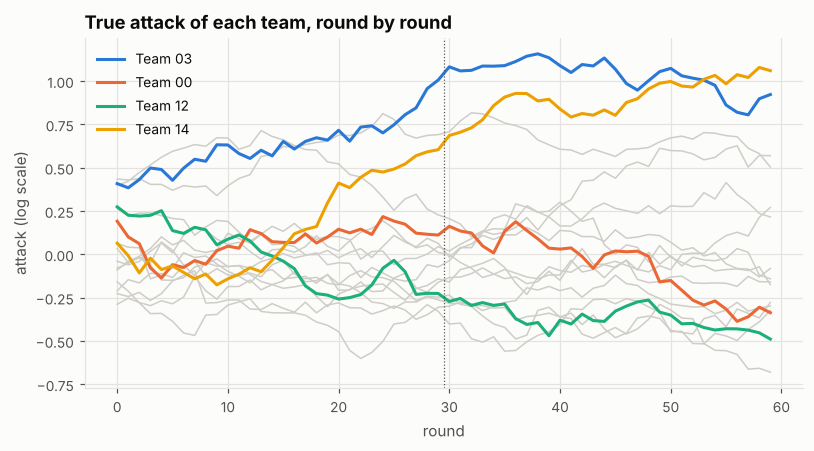

In [3]:
true_a = truth["attack"]
show = (true_a.iloc[:, -1] - true_a.iloc[:, 0]).abs().sort_values().index[-4:]
fig, ax = plt.subplots()
for team in true_a.index:
    ax.plot(true_a.loc[team], color="#cfcdc7", lw=1)
for team, c in zip(show, SERIES):
    ax.plot(true_a.loc[team], color=c, lw=2, label=team)
ax.axvline(n_periods / 2 - .5, color=TEXT_2, lw=0.8, ls=":")
ps.finish(ax, "True attack of each team, round by round", "round",
          "attack (log scale)", legend=True)

In colour, the four teams whose attack moved the most; the dotted line marks
the start of the second season.

## 3. Choosing $\sigma$

One-round-ahead forecasts over the second season (every third round, to keep
the notebook quick): mean log-likelihood per observed goal count.

In [4]:
grid = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2]
sigma, table = ex.choose_sigma(matches, grid, first=n_periods // 2, step=3)
print("chosen sigma: %.3f (true %.3f)" % (sigma, truth["sigma"]))
table.to_frame().T.round(4)

chosen sigma: 0.050 (true 0.050)


sigma,0.005,0.010,0.020,0.050,0.100,0.200
log score,-1.328,-1.3261,-1.3204,-1.3092,-1.3187,-1.3591


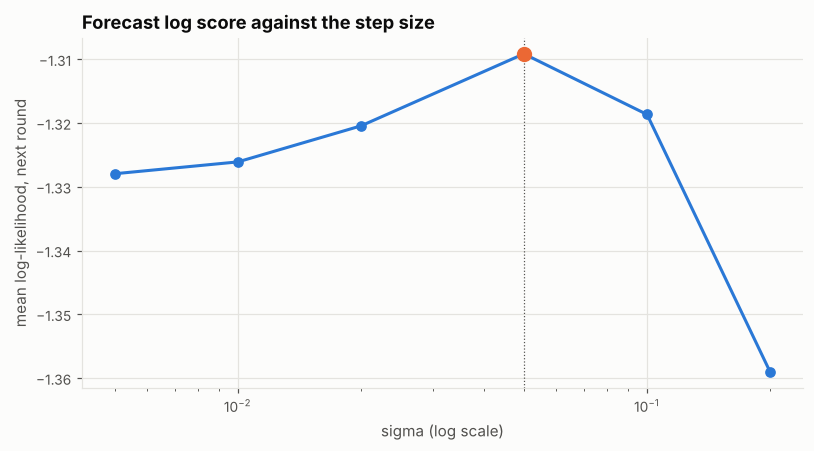

In [5]:
fig, ax = plt.subplots()
ax.plot(table.index, table.values, "o-", color=BLUE)
ax.plot([sigma], [table[sigma]], "o", color=ORANGE, markersize=9, zorder=3)
ax.axvline(truth["sigma"], color=TEXT_2, lw=0.8, ls=":")
ax.set_xscale("log")
ps.finish(ax, "Forecast log score against the step size", "sigma (log scale)",
          "mean log-likelihood, next round")

The score peaks at the true step size (dotted line). Too small a $\sigma$ keeps
stale strengths; too large a $\sigma$ chases the noise of the last few matches.
The differences are small per goal count, but they add up over a season of
forecasts. With smaller true steps or fewer matches the curve is flatter, and
$\sigma$ is harder to tell apart from 0.

## 4. Model and its graph

The same graph as the static model, with attack and defence of shape
(teams, rounds) and the random walk as a regularization of both.

In [6]:
static, teams = ex.fit(matches)
dynamic, _ = ex.fit(matches, sigma)
dynamic.graph()

<Graph: 10 nodes, 12 edges>

## 5. Estimates

The fitted attack of the four teams above, with 95% intervals, against the
truth and against the static estimate (one value for the 60 rounds).

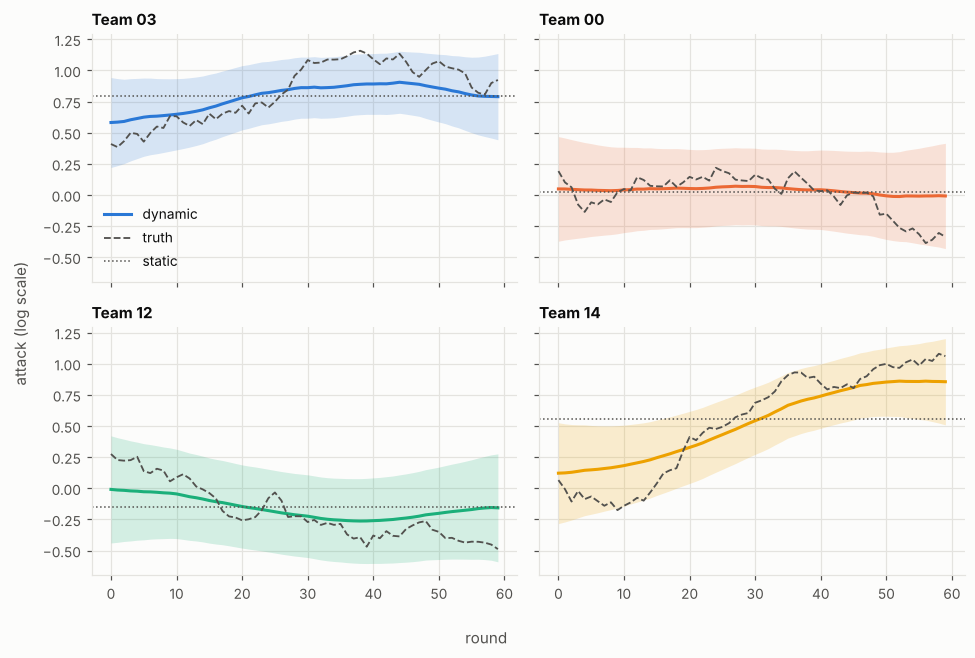

In [7]:
est = dynamic.get_params(labeled=True)[0]          # teams x rounds
se = pd.DataFrame(np.ma.getdata(dynamic.std_error()[0]),
                  index=est.index, columns=est.columns)
a_static = static.get_params(labeled=True)[0]
rounds = np.arange(n_periods)

fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True, sharey=True)
for ax, team, c in zip(axes.ravel(), show, SERIES):
    ax.fill_between(rounds, est.loc[team] - 1.96 * se.loc[team],
                    est.loc[team] + 1.96 * se.loc[team], color=c, alpha=.18, lw=0)
    ax.plot(rounds, est.loc[team], color=c, label="dynamic")
    ax.plot(rounds, true_a.loc[team], color=TEXT_2, lw=1.2, ls="--", label="truth")
    ax.axhline(a_static[team], color=TEXT_2, lw=1, ls=":", label="static")
    ax.set_title(team, fontsize=10)
axes[0, 0].legend(loc="best")
fig.supxlabel("round", fontsize=10, color=TEXT_2)
fig.supylabel("attack (log scale)", fontsize=10, color=TEXT_2)
plt.tight_layout()

The dynamic fit follows the broad trend of each team (Team 14's rise), not
the round-to-round noise: with one match per round, a few weeks of form are
not distinguishable from luck. The static fit is close to the average of the
path, wrong at both ends. The intervals widen at the first and last rounds,
where only one side of the path has data, and that is also where the dynamic
fit lags the truth most (Team 00's late decline).

### Error against the truth, round by round

Root mean square error of the attack over the 16 teams, per round.

,static,dynamic
mean RMSE,0.191,0.158


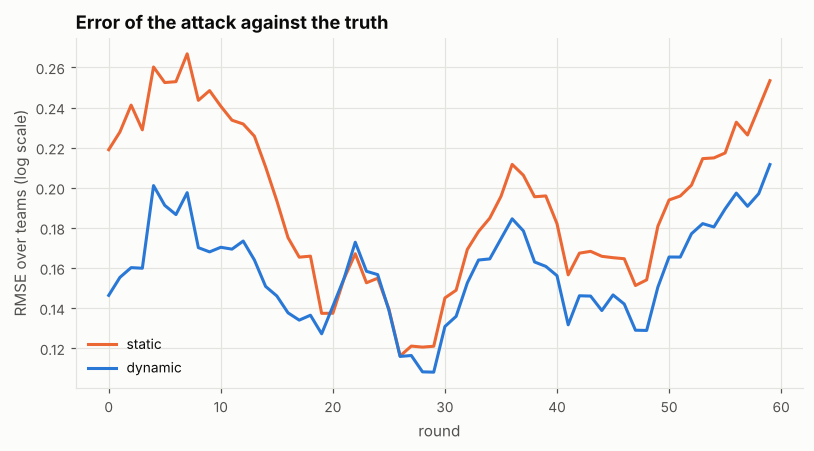

In [8]:
err_dynamic = np.sqrt(((est.values - true_a.values) ** 2).mean(0))
err_static = np.sqrt(((a_static.values[:, None] - true_a.values) ** 2).mean(0))
fig, ax = plt.subplots()
ax.plot(rounds, err_static, color=ORANGE, label="static")
ax.plot(rounds, err_dynamic, color=BLUE, label="dynamic")
ps.finish(ax, "Error of the attack against the truth", "round",
          "RMSE over teams (log scale)", legend=True)
pd.Series({"static": err_static.mean(), "dynamic": err_dynamic.mean()},
          name="mean RMSE").round(3).to_frame().T

The static model is good only where the path crosses its average; the
dynamic one is better almost everywhere, by most at the two ends. The last
rounds, the ones that matter for the next match, remain the hardest for both:
the end of the path is pinned down by past matches only.

## 6. Home advantage and forecasts

The home advantage stays a single parameter.

In [9]:
dynamic.summary().loc[["home"]].round(4)

,,estimate,std_error,z,p_value,ci_95%_lower,ci_95%_upper,fixed
param,label,,,,,,,
home,,0.2391,0.0586,4.0801,0.0,0.1243,0.354,False


For a match in the next round the forecast is the last fitted strengths. Its
variance on the log scale is that of the last round plus $2\sigma^2$ per round
ahead (attack and defence both move).

In [10]:
strength = est.iloc[:, -1] + dynamic.get_params(labeled=True)[1].iloc[:, -1]
best, worst = strength.idxmax(), strength.idxmin()
rows = {}
for h in (1, 5, 10):
    value, se_ = ex.expected_goals(dynamic, teams, best, worst, n_periods - 1, h)
    rows[h] = [value[0], se_[0], value[1], se_[1]]
pd.DataFrame(rows, index=[best + " (home)", "se", worst + " (away)", "se"]
             ).T.rename_axis("rounds ahead").round(2)

,Team 03 (home),se,Team 07 (away),se
rounds ahead,,,,
1,4.31,1.11,0.41,0.14
5,4.31,1.26,0.41,0.15
10,4.31,1.43,0.41,0.16


## 7. With real data

`fit(matches, sigma)` needs one row per match with the columns `home`,
`away`, `home_goals`, `away_goals` and `period` (0, 1, 2, ...): the round,
or the week or month of the match date. With periods of unequal length, give
`RandomWalk` one step size per gap, $\sigma\sqrt{\text{gap}}$, so that a summer
break allows a larger change than a week. Choose $\sigma$ with
`choose_sigma` on the last part of the data before forecasting with it.